# Module 2 · Notebook 3: The experiment

**Question: why does attention divide the scores by $\sqrt{d}$?**

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right) V$$

Every explanation says "to stop softmax from saturating". This notebook measures what that means, and compares three choices: **no scaling**, **÷√d**, and **÷d** (the obvious question: why the square root, and not $d$ itself?).

| Step | What we do |
|---|---|
| 1 | Theory: how big are the scores, and what does softmax do to the gradient |
| 2 | Measure at initialization: attention entropy and gradient size, for head sizes 8 to 1024 |
| 3 | Train a single attention head on a small task, sweeping the learning rate |
| 4 | The chart and the findings |

**Runtime:** about 10 minutes on a laptop CPU (Step 3 trains 108 small models).

In [11]:
import sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

LAB = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(LAB / "01-autograd"))
from autograd import Tensor, softmax

print("python", sys.version.split()[0], "| numpy", np.__version__)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

# the three choices, each with a fixed color and line style
SCALES = {
    "÷√d":        {"fn": lambda d: 1 / np.sqrt(d), "color": "#2a78d6", "ls": "-"},
    "no scaling": {"fn": lambda d: 1.0,            "color": "#eb6834", "ls": "--"},
    "÷d":         {"fn": lambda d: 1 / d,          "color": "#1baf7a", "ls": ":"},
}

def softmax_np(z):
    z = z - z.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

python 3.12.15 | numpy 2.5.3


## Step 1: Theory

**How big are the scores?** After LayerNorm and a standard initialization, the entries of $q$ and $k$ are roughly independent with mean 0 and variance 1. A score is a sum of $d$ such products:

$$q \cdot k = \sum_{i=1}^{d} q_i k_i, \qquad \text{Var}(q \cdot k) = d \quad\Rightarrow\quad \text{std}(q \cdot k) = \sqrt{d}$$

So the three choices give scores with standard deviation:

| Choice | std of the scores | as $d$ grows |
|---|---|---|
| no scaling | $\sqrt{d}$ | grows: 4 at $d = 16$, 32 at $d = 1024$ |
| **÷√d** | **1** | **constant** |
| ÷d | $1/\sqrt{d}$ | shrinks toward 0 |

**What does softmax do with that?** Softmax turns scores $s$ into weights $p$. Its backward pass is: for an incoming gradient $g = \partial L/\partial p$,

$$\frac{\partial L}{\partial s_i} = p_i \left(g_i - \textstyle\sum_j p_j g_j\right)$$

Two extremes:
- **Scores very spread out** → $p$ is nearly one-hot ($p_i \approx 1$ for one token, $\approx 0$ for the rest). Then every term is $\approx 0$: for the winner $g_i - \sum_j p_j g_j \approx g_i - g_i = 0$, for the others $p_i \approx 0$. **The gradient vanishes**, and the model gets almost no signal about which tokens it should attend to instead. This is **saturation**.
- **Scores nearly equal** → $p$ is nearly uniform. The gradient is fine, but the head **cannot focus** on anything until its weights grow a lot.

**Quick proof that the formula above is what the engine computes:**

In [12]:
rng = np.random.default_rng(0)
s_np, g_np = rng.standard_normal(10) * 3, rng.standard_normal(10)

s = Tensor(s_np[None])
(softmax(s, axis=-1) * g_np).sum().backward()          # L = sum(g * softmax(s))  =>  dL/dp = g

p = softmax_np(s_np)
closed_form = p * (g_np - (p * g_np).sum())
print(f"max |engine - closed form| = {np.abs(s.grad[0] - closed_form).max():.1e}")

max |engine - closed form| = 4.9e-17


## Step 2: Measure at initialization

For each head size $d$ from 8 to 1024 and each choice of scaling: 2,000 random queries, each scored against $T = 32$ random keys (unit-variance entries, as at initialization). For every query we record:

- **entropy** of its attention weights, divided by the maximum $\log T$: **1 = uniform** over all 32 tokens, **0 = all weight on one token**;
- **the largest weight** in the row;
- **the size of the gradient that reaches the scores** through softmax, for a random incoming gradient (the formula from Step 1). We report the median over the 2,000 queries.

(Why 2,000: the gradient at $d = 1024$ is a median over rows that are almost all saturated, so it is noisy. With 300 queries it moved by more than 5× between random seeds; with 2,000 it settles to within about 3×.)

In [13]:
T = 32
dims = [8, 16, 32, 64, 128, 256, 512, 1024]

def measure_init(dims, T=32, trials=2000, chunk=250, seed=0):
    # same code as run.py, so both print identical numbers
    rng = np.random.default_rng(seed)
    res = {name: {"std": [], "entropy": [], "max_w": [], "grad": []} for name in SCALES}
    for d in dims:
        acc = {name: {"s": [], "ent": [], "mw": [], "g": []} for name in SCALES}
        for _ in range(trials // chunk):              # chunks, so d = 1024 doesn't need GBs of memory
            q = rng.standard_normal((chunk, 1, d))
            k = rng.standard_normal((chunk, T, d))
            g = rng.standard_normal((chunk, T))      # a random incoming gradient on the weights
            raw = (q @ k.transpose(0, 2, 1))[:, 0, :]
            for name, cfg in SCALES.items():
                s = raw * cfg["fn"](d)
                p = softmax_np(s)
                plogp = np.where(p > 0, p * np.log(np.where(p > 0, p, 1.0)), 0.0)
                acc[name]["s"].append(s)
                acc[name]["ent"].append(-plogp.sum(-1) / np.log(T))
                acc[name]["mw"].append(p.max(-1))
                acc[name]["g"].append(np.linalg.norm(p * (g - (p * g).sum(-1, keepdims=True)), axis=-1))
        for name in SCALES:
            a = {key: np.concatenate(v) for key, v in acc[name].items()}
            res[name]["std"].append(a["s"].std())
            res[name]["entropy"].append(a["ent"].mean())
            res[name]["max_w"].append(a["mw"].mean())
            res[name]["grad"].append(np.median(a["g"]))
    return res

init = measure_init(dims)

for name in SCALES:
    print(f"{name}")
    print(f"   {'d':>5s} {'score std':>10s} {'entropy':>8s} {'max weight':>11s} {'gradient':>9s}")
    for i, d in enumerate(dims):
        r = init[name]
        print(f"   {d:5d} {r['std'][i]:10.2f} {r['entropy'][i]:8.2f} {r['max_w'][i]:11.2f} {r['grad'][i]:9.1e}")

÷√d
       d  score std  entropy  max weight  gradient
       8       1.01     0.87        0.17   2.1e-01
      16       1.00     0.87        0.16   2.1e-01
      32       1.00     0.87        0.16   2.2e-01
      64       1.00     0.87        0.16   2.1e-01
     128       1.00     0.87        0.16   2.2e-01
     256       1.00     0.87        0.17   2.2e-01
     512       1.00     0.87        0.16   2.2e-01
    1024       1.00     0.87        0.17   2.2e-01
no scaling
       d  score std  entropy  max weight  gradient
       8       2.85     0.48        0.50   2.5e-01
      16       3.99     0.33        0.63   2.1e-01
      32       5.65     0.22        0.74   1.6e-01
      64       7.98     0.14        0.82   8.0e-02
     128      11.29     0.10        0.87   3.5e-02
     256      16.06     0.07        0.91   7.5e-03
     512      22.55     0.05        0.93   1.2e-03
    1024      32.16     0.03        0.96   5.9e-05
÷d
       d  score std  entropy  max weight  gradient
       8     

## Step 3: Does it matter for training?

Initialization numbers are suggestive, but the real question is whether a model **learns** worse. A minimal test with one attention head:

**The task: find the matching token.** The input is 16 random token vectors. The query is an exact copy of one of them, at a random position. The head's output should be that token's vector. To solve it, the head must learn $W_q$ and $W_k$ so that the copy gets all the attention.

- learned: $W_q$, $W_k$ (each $d \times d$, standard initialization); values are the tokens themselves;
- loss: mean squared error between the attention output and the target token;
- plain SGD, batch 32, 300 steps, fresh random data every step;
- **success** = the head attends most to the right token in at least 95% of the last 50 batches.

The comparison that matters is **across learning rates**: for each scaling and head size, which learning rates train successfully?

**Plus a control.** If the learning-rate window shrinks, is it *because* attention starts out saturated? To test that, a fourth setup: **no scaling, but $W_q$ and $W_k$ start $d^{-1/4}$ smaller**. Then the scores start with spread 1, exactly like ÷√d, so nothing is saturated at the start. If saturation were the cause, this control's window should stay put. (At initialization it is identical to ÷√d, so it only appears in the training results.)

In [14]:
def swap_last2(t):
    n = t.data.ndim
    return t.transpose(tuple(range(n - 2)) + (n - 1, n - 2))

def train_retrieval(d, scale, lr, init_mult=1.0, steps=300, B=32, T=16, seed=0):
    r = np.random.default_rng(seed)
    Wq = Tensor(r.standard_normal((d, d)) / np.sqrt(d) * init_mult)
    Wk = Tensor(r.standard_normal((d, d)) / np.sqrt(d) * init_mult)
    data = np.random.default_rng(seed + 1)
    accs = []
    for step in range(steps):
        x = data.standard_normal((B, T, d))
        j = data.integers(0, T, B)
        query = x[np.arange(B), j][:, None, :]            # an exact copy of token j
        Wq.grad, Wk.grad = np.zeros_like(Wq.data), np.zeros_like(Wk.data)
        p = softmax(((Tensor(query) @ Wq) @ swap_last2(Tensor(x) @ Wk)) * scale, axis=-1)
        loss = ((p @ Tensor(x) - query) ** 2).mean()
        loss.backward()
        if not np.isfinite(loss.data):
            return float("nan")
        Wq.data -= lr * Wq.grad
        Wk.data -= lr * Wk.grad
        accs.append((p.data[:, 0].argmax(-1) == j).mean())
    return float(np.mean(accs[-50:]))

LRS = [0.03, 0.1, 0.3, 1, 3, 10, 30, 100]
CONTROL = "no scaling, small init"                   # no scaling, Wq/Wk start d**-0.25 smaller
RUNS = [(d, name) for d in [16, 64, 256] for name in list(SCALES) + [CONTROL]]
RUNS += [(512, "no scaling"), (512, "÷√d")]           # d = 512 is slow, so only the two that matter most
LRS_512 = [0.03, 0.1, 0.3, 1, 3, 10]

results = {}
t0 = time.perf_counter()
for d, name in RUNS:
    lrs = LRS_512 if d == 512 else LRS
    if name == CONTROL:
        scale, init_mult = 1.0, d ** -0.25
    else:
        scale, init_mult = SCALES[name]["fn"](d), 1.0
    results[d, name] = {lr: train_retrieval(d, scale, lr, init_mult) for lr in lrs}
    print(f"d={d:4d} {name:22s} " + "  ".join(f"lr={lr:g}:{a:.2f}" for lr, a in results[d, name].items())
          + f"   [{time.perf_counter() - t0:.0f}s]", flush=True)

d=  16 ÷√d                    lr=0.03:0.87  lr=0.1:0.97  lr=0.3:0.99  lr=1:0.99  lr=3:0.99  lr=10:0.96  lr=30:0.07  lr=100:0.06   [2s]
d=  16 no scaling             lr=0.03:0.95  lr=0.1:0.98  lr=0.3:0.99  lr=1:0.99  lr=3:0.55  lr=10:0.12  lr=30:0.07  lr=100:0.10   [4s]
d=  16 ÷d                     lr=0.03:0.27  lr=0.1:0.78  lr=0.3:0.96  lr=1:0.99  lr=3:0.99  lr=10:0.99  lr=30:0.97  lr=100:0.08   [7s]
d=  16 no scaling, small init lr=0.03:0.97  lr=0.1:0.99  lr=0.3:0.99  lr=1:0.99  lr=3:0.76  lr=10:0.13  lr=30:0.07  lr=100:0.06   [9s]
d=  64 ÷√d                    lr=0.03:0.90  lr=0.1:1.00  lr=0.3:1.00  lr=1:1.00  lr=3:1.00  lr=10:0.84  lr=30:0.09  lr=100:0.10   [20s]
d=  64 no scaling             lr=0.03:0.98  lr=0.1:1.00  lr=0.3:1.00  lr=1:0.97  lr=3:0.11  lr=10:0.06  lr=30:0.08  lr=100:0.08   [30s]
d=  64 ÷d                     lr=0.03:0.09  lr=0.1:0.23  lr=0.3:0.88  lr=1:1.00  lr=3:1.00  lr=10:1.00  lr=30:1.00  lr=100:0.42   [39s]
d=  64 no scaling, small init lr=0.03:1.00  lr=0.1:1

In [15]:
def window(accs, threshold=0.95):
    ok = [lr for lr, a in accs.items() if a >= threshold]
    return (min(ok), max(ok)) if ok else None

print(f"{'scaling':22s} | " + " | ".join(f"d = {d:<4d}" for d in [16, 64, 256, 512]))
for name in list(SCALES) + [CONTROL]:
    cells = []
    for d in [16, 64, 256, 512]:
        w = window(results[d, name]) if (d, name) in results else None
        cells.append("not run   " if (d, name) not in results else (f"{w[0]:g} – {w[1]:g}".ljust(10) if w else "none      "))
    print(f"{name:22s} | " + " | ".join(cells))
print("\n(range of learning rates that reach >= 95% accuracy)")

scaling                | d = 16   | d = 64   | d = 256  | d = 512 
÷√d                    | 0.1 – 10   | 0.1 – 3    | 0.1 – 3    | 0.1 – 3   
no scaling             | 0.1 – 1    | 0.03 – 1   | 0.03 – 0.3 | 0.03 – 0.1
÷d                     | 0.3 – 30   | 1 – 30     | 1 – 100    | not run   
no scaling, small init | 0.03 – 1   | 0.03 – 1   | 0.03 – 0.3 | not run   

(range of learning rates that reach >= 95% accuracy)


## Step 4: The chart

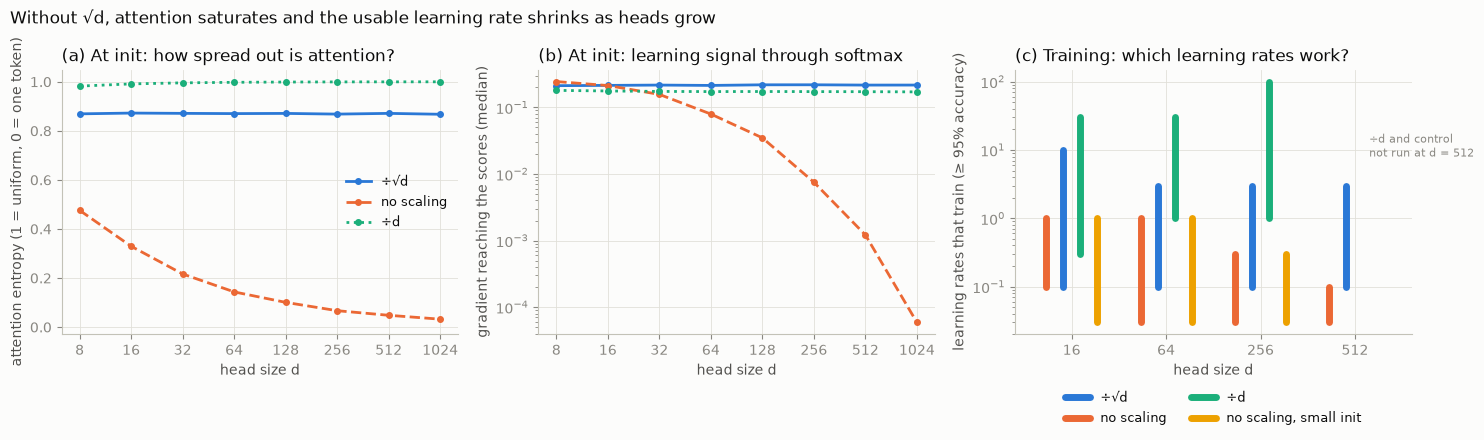

In [16]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.6))

for name, cfg in SCALES.items():
    ax1.plot(dims, init[name]["entropy"], color=cfg["color"], ls=cfg["ls"], marker="o", ms=4, label=name)
    ax2.plot(dims, init[name]["grad"], color=cfg["color"], ls=cfg["ls"], marker="o", ms=4, label=name)

for ax in (ax1, ax2):
    ax.set_xscale("log", base=2)
    ax.set_xticks(dims, [str(d) for d in dims])
    ax.set_xlabel("head size d")
ax1.set_ylim(-0.03, 1.05)
ax1.set_ylabel("attention entropy (1 = uniform, 0 = one token)")
ax1.set_title("(a) At init: how spread out is attention?", loc="left")
ax1.legend(loc="center right", fontsize=9)
ax2.set_yscale("log")
ax2.set_ylabel("gradient reaching the scores (median)")
ax2.set_title("(b) At init: learning signal through softmax", loc="left")

# (c) the window of learning rates that train, per head size and scaling
# the control goes last, next to ÷d rather than next to orange (orange and yellow are hard to tell apart)
offsets = {"no scaling": -0.27, "÷√d": -0.09, "÷d": 0.09, CONTROL: 0.27}
colors = {name: cfg["color"] for name, cfg in SCALES.items()} | {CONTROL: "#eda100"}
train_dims = [16, 64, 256, 512]
for name, color in colors.items():
    labeled = False
    for i, d in enumerate(train_dims):
        if (d, name) not in results:
            continue
        w = window(results[d, name])
        if w is None:
            continue
        x = i + offsets[name]
        ax3.plot([x, x], [w[0], w[1]], color=color, lw=5, solid_capstyle="round",
                 label=None if labeled else name)
        labeled = True
ax3.set_yscale("log")
ax3.set_xticks(range(len(train_dims)), [str(d) for d in train_dims])
ax3.set_xlim(-0.6, len(train_dims) - 0.4)
ax3.set_xlabel("head size d")
ax3.set_ylabel("learning rates that train (≥ 95% accuracy)")
ax3.set_title("(c) Training: which learning rates work?", loc="left")
ax3.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9)   # below: 4 entries would cover the bars
ax3.text(len(train_dims) - 1 + 0.15, 8, "÷d and control\nnot run at d = 512", color=MUTED, fontsize=8, ha="left")

fig.suptitle("Without √d, attention saturates and the usable learning rate shrinks as heads grow",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

## Findings

**1. Without scaling, attention saturates as the head grows, exactly as the theory says.** The score spread grows like $\sqrt{d}$ (2.8 at $d = 8$, 32 at $d = 1024$). At $d = 1024$ the entropy is 0.03 and the largest weight averages 0.96: each query puts almost everything on one token, chosen at random before any learning has happened.

**2. Saturation kills the learning signal.** The gradient reaching the scores through softmax drops from 0.25 at $d = 8$ to **5.9e-5 at $d = 1024$**, about **3,700× smaller** than with ÷√d (0.22). The exact ratio depends on the random draw (it ranged from roughly 3,000× to 9,000× across the seeds I tried), but it is thousands of times smaller every time.

**3. ÷√d is the one choice that does not depend on $d$.** Score spread 1.00, entropy 0.87, gradient 0.22, at every head size from 8 to 1024.

**4. ÷d overcorrects.** Its gradient is fine (0.17), but the attention starts **completely uniform** (entropy 1.00): every token gets the same weight, and the head has to grow its weights a lot before it can focus on anything.

**5. In training, what shows up is a shrinking learning-rate window.** On the "find the matching token" task:
- **no scaling:** the largest learning rate that still trains falls **10×**, from 1 at $d = 16$ to 0.1 at $d = 512$;
- **÷√d:** the window stays at **0.1 – 3** for every size tested (up to 10 at $d = 16$);
- **÷d:** the window stays wide but **drifts upward** (lower edge 0.3 → 1), so the learning rate has to change with the head size.

**6. The control: saturation is not why the window shrinks.** With no scaling but a smaller init, the scores start exactly like ÷√d (spread 1, nothing saturated), yet the window shrinks just like plain no-scaling: 0.03 – 1, 0.03 – 1, 0.03 – 0.3 for $d$ = 16, 64, 256. My first explanation, "saturation makes training fragile", was wrong. The scale factor does two jobs: it sets how big the scores are at the start, **and** how far each update moves them. Without √d, the same learning rate moves the scores further as $d$ grows, so the learning rate has to shrink. ÷d is never saturated and its window still drifts, for the same reason in the other direction.

So the full answer to "why √d": **without it, attention starts saturated, and each update moves the scores further as $d$ grows, so the usable learning rate shrinks. √d keeps both independent of $d$**, which is what lets one learning rate work for every head size.

**Limits of this experiment:**
- one task, one random seed, a single attention head, plain SGD. Adam rescales gradients per parameter, which hides part of the effect; Module 3 trains with AdamW;
- 0.03 was the smallest learning rate tried, so window edges at 0.03 are the edge of the grid, not a measured limit;
- training stops at $d = 512$ (÷d and the control at 256) because NumPy is slow at larger sizes. The initialization numbers go to 1024 and say the effect keeps growing.